# Large-network plotting example: 2,000 nodes

This example uses **three synthetic conditions, 2,000 nodes per condition, and
8,000 directed edges per condition**. A community background, changing module,
and changing hub make the plotting controls visible. The data are illustrative;
this is not a biological validation dataset or a p-value benchmark.

We calculate scores once using sparse storage, then draw:

1. The full network with the current automatic defaults.
2. The full network with a NetworkX spring layout.
3. The 40 nodes with the highest supplied rewiring scores.
4. A small one-hop neighborhood.
5. The same neighborhood across the three conditions with shared positions.

Running the notebook writes the CSVs and PNGs into this folder's `outputs/`
directory. Example outputs are included in the repository so they can also be
viewed without running the code.

In [1]:
%matplotlib inline
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
from platform import python_version
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Support a kernel started here, at the repository root, or in dynet-py.
candidates = [
    Path.cwd(),
    Path.cwd() / "dynet-py" / "examples" / "large_network_demo",
    Path.cwd() / "examples" / "large_network_demo",
]
DEMO_DIR = next((path for path in candidates if (path / "synthetic_networks.py").exists()), None)
if DEMO_DIR is None:
    raise RuntimeError("Start the notebook in its folder, the repository root, or the dynet-py directory.")
sys.path.insert(0, str(DEMO_DIR))
from synthetic_networks import make_networks
from dynet_py import prepare_networks, rewiring_analysis, rewiring_plot, small_multiples_plot

N_NODES = 2000
SEED = 20261019
OUTPUT_DIR = DEMO_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
timings = []
views = []

## Prepare the synthetic networks and calculate the full scores

Inputs use `source`, `target`, and `weight`. Preparation runs once. Every plot
below consumes the same prepared collection and the same full score table.
We use `backend="sparse"`; no dense adjacency tensor is requested.

Any timings displayed here are single local observations, not a controlled
performance benchmark. They do not measure p-value calculations.

In [2]:
started = perf_counter()
raw_networks = make_networks(n_nodes=N_NODES, seed=SEED)
timings.append({"step": "generate synthetic inputs", "seconds": perf_counter() - started})

started = perf_counter()
networks = prepare_networks(raw_networks)
timings.append({"step": "prepare inputs", "seconds": perf_counter() - started})

started = perf_counter()
scores = rewiring_analysis(networks, backend="sparse")
timings.append({"step": "sparse rewiring scores", "seconds": perf_counter() - started})
scores_before_plotting = scores.copy(deep=True)
assert len(scores) == N_NODES

input_summary = pd.DataFrame([
    {"condition": name, "nodes": N_NODES, "directed_edges": len(frame)}
    for name, frame in raw_networks.items()
])
union_edges = pd.concat(raw_networks.values(), ignore_index=True)[["source", "target"]].drop_duplicates()
print(f"Directed union edges: {len(union_edges):,}")
display(input_summary)
display(scores.sort_values("rewiring", ascending=False).head(10))

# A moderately sized neighborhood is more useful than the changing hub's huge one.
candidates = scores.loc[scores["degree"].between(10, 25)].sort_values("rewiring", ascending=False)
FOCUS_NODE = candidates.iloc[0]["name"]
print("Focal node:", FOCUS_NODE)

def save_view(figure, filename, title, drawn_nodes, started):
    figure.savefig(OUTPUT_DIR / filename, dpi=140, bbox_inches="tight")
    timings.append({"step": filename, "seconds": perf_counter() - started})
    views.append({"view": title, "displayed_nodes": drawn_nodes, "file": filename})
    display(figure)
    plt.close(figure)

Directed union edges: 10,983


,condition,nodes,directed_edges
0,condition_1,2000,8000
1,condition_2,2000,8000
2,condition_3,2000,8000


,name,rewiring,degree,degree_corrected_rewiring
0,node_0000,89.336539,273.0,0.327240
11,node_0011,21.028175,68.0,0.309238
9,node_0009,18.669336,62.0,0.301118
13,node_0013,17.549875,55.0,0.319089
32,node_0032,17.170305,58.0,0.296040
48,node_0048,17.091625,59.0,0.289689
22,node_0022,16.806315,56.0,0.300113
43,node_0043,16.775234,58.0,0.289228
20,node_0020,16.484949,59.0,0.279406
30,node_0030,16.450586,57.0,0.288607


Focal node: node_1563


## 1. Full graph with the current defaults

For more than 500 displayed nodes, `layout="auto"` uses circular positions and
labels only the ten highest-scoring nodes. The full graph still contains every
edge and can remain visually dense. This view shows the limits of drawing an
entire large network at once.

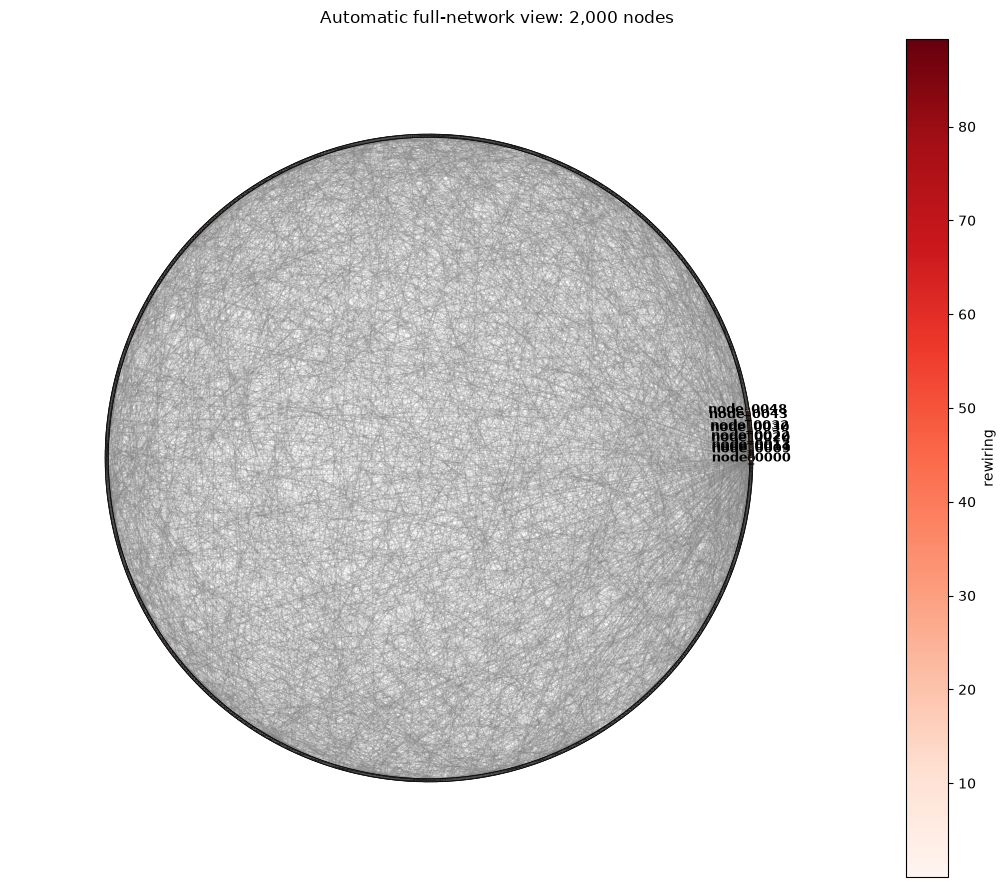

In [3]:
started = perf_counter()
figure = rewiring_plot(networks, scores, figsize=(12, 9))
figure.suptitle(f"Automatic full-network view: {N_NODES:,} nodes")
figure.tight_layout()
save_view(figure, "01_full_network_auto.png", "Full network: automatic", N_NODES, started)

## 2. Full graph with an explicit NetworkX spring layout

The layout changes positions rather than scores or edges. All 2,000 nodes remain
visible. We suppress node labels in this overview so the structure is easier to
inspect; individual nodes are identified in the filtered views below.

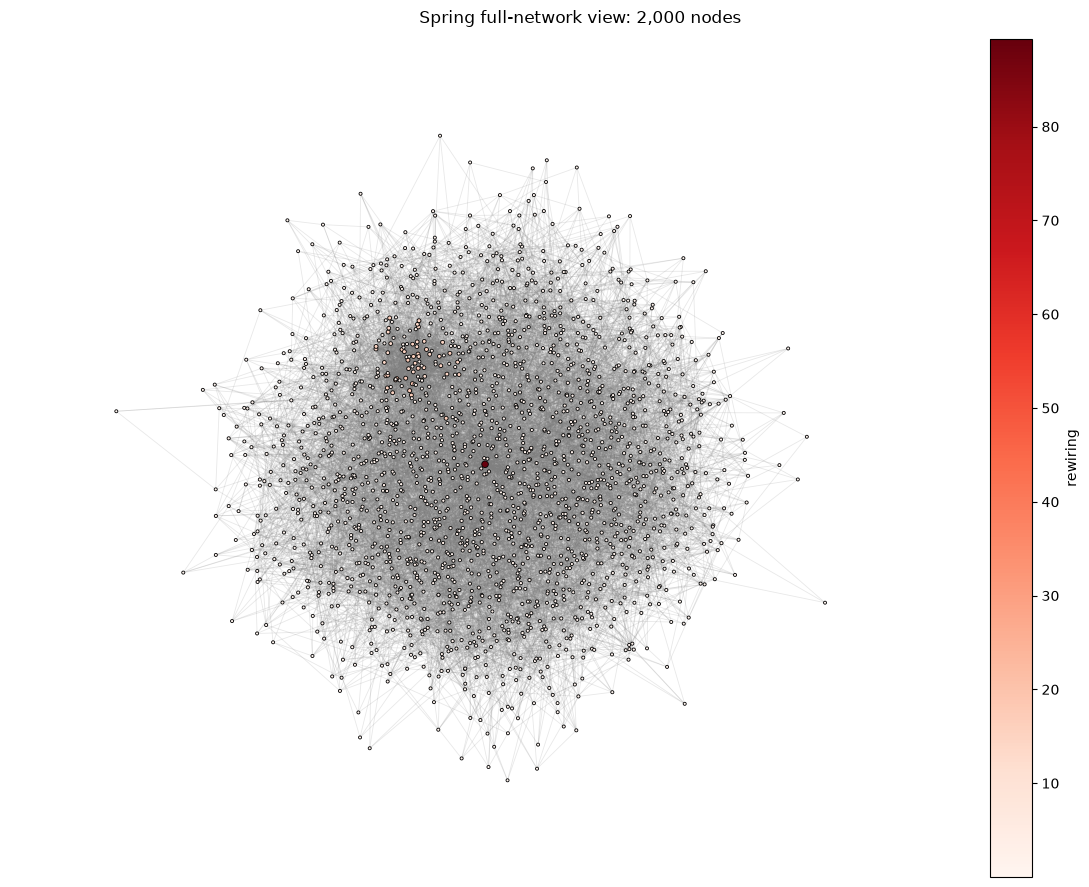

In [4]:
started = perf_counter()
figure = rewiring_plot(networks, scores, layout="spring", labels="none", seed=SEED, figsize=(12, 9))
figure.suptitle(f"Spring full-network view: {N_NODES:,} nodes")
figure.tight_layout()
save_view(figure, "02_full_network_spring.png", "Full network: spring", N_NODES, started)

## 3. Top 40 nodes by rewiring

`top_n=40` keeps the 40 highest-scoring nodes and the edges **between those nodes**.
It does not automatically add their other neighbors. Automatic labels show ten
nodes. Color limits still come from the full 2,000-node score table.

The reported degrees and scores remain values calculated on the full networks.
They are not recalculated from the displayed subgraph.

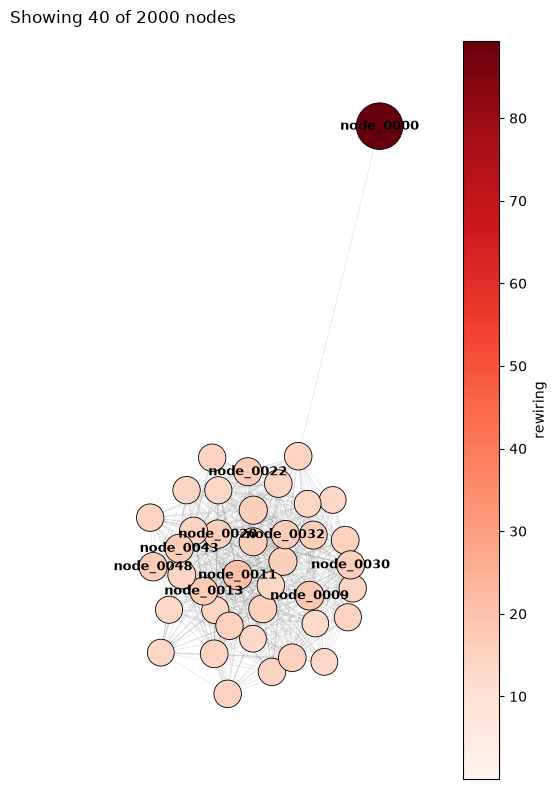

,name,rewiring,degree
0,node_0000,89.336539,273.0
11,node_0011,21.028175,68.0
9,node_0009,18.669336,62.0
13,node_0013,17.549875,55.0
32,node_0032,17.170305,58.0
48,node_0048,17.091625,59.0
22,node_0022,16.806315,56.0
43,node_0043,16.775234,58.0
20,node_0020,16.484949,59.0
30,node_0030,16.450586,57.0


In [5]:
started = perf_counter()
figure = rewiring_plot(networks, scores, top_n=40, layout="spring", labels="auto", seed=SEED, figsize=(10, 8))
save_view(figure, "03_top_40_nodes.png", "Top 40 by rewiring", 40, started)
display(scores.sort_values("rewiring", ascending=False).head(40)[["name", "rewiring", "degree"]])

## 4. A focused neighborhood

`focus_node` and `radius=1` select immediate incoming and outgoing neighbors in
the network union. We cap the view at 25 nodes and label the focal node plus a
few of its highest-scoring neighbors. The focal node is always retained.

Neighborhood around node_1563: 20 union nodes, displaying 20.


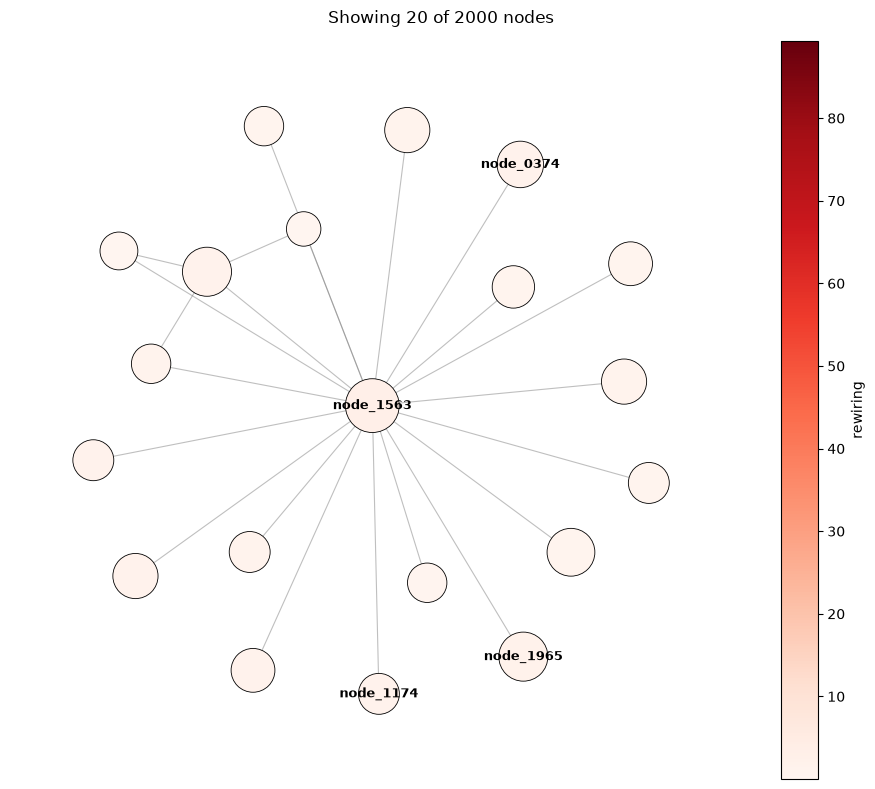

In [6]:
incident = union_edges[(union_edges["source"] == FOCUS_NODE) | (union_edges["target"] == FOCUS_NODE)]
neighbor_names = {FOCUS_NODE, *incident["source"], *incident["target"]}
neighbor_scores = scores.loc[scores["name"].isin(neighbor_names)].sort_values("rewiring", ascending=False)
focus_labels = [FOCUS_NODE, *neighbor_scores["name"].head(4)]
NEIGHBORHOOD_SIZE = min(25, len(neighbor_names))
print(f"Neighborhood around {FOCUS_NODE}: {len(neighbor_names)} union nodes, displaying {NEIGHBORHOOD_SIZE}.")

started = perf_counter()
figure = rewiring_plot(
    networks, scores, focus_node=FOCUS_NODE, radius=1, top_n=25,
    layout="spring", labels=focus_labels, seed=SEED, figsize=(10, 8),
)
save_view(figure, "04_focused_neighborhood.png", "One-hop neighborhood", NEIGHBORHOOD_SIZE, started)

## 5. Compare the neighborhood across conditions

The panels share node positions; arrows retain each condition's directed edges.
The focal node is red. Only it is labeled here to reduce crowding. The panel cap
uses union degree, while `rewiring_plot(top_n=...)` ranks by rewiring score.

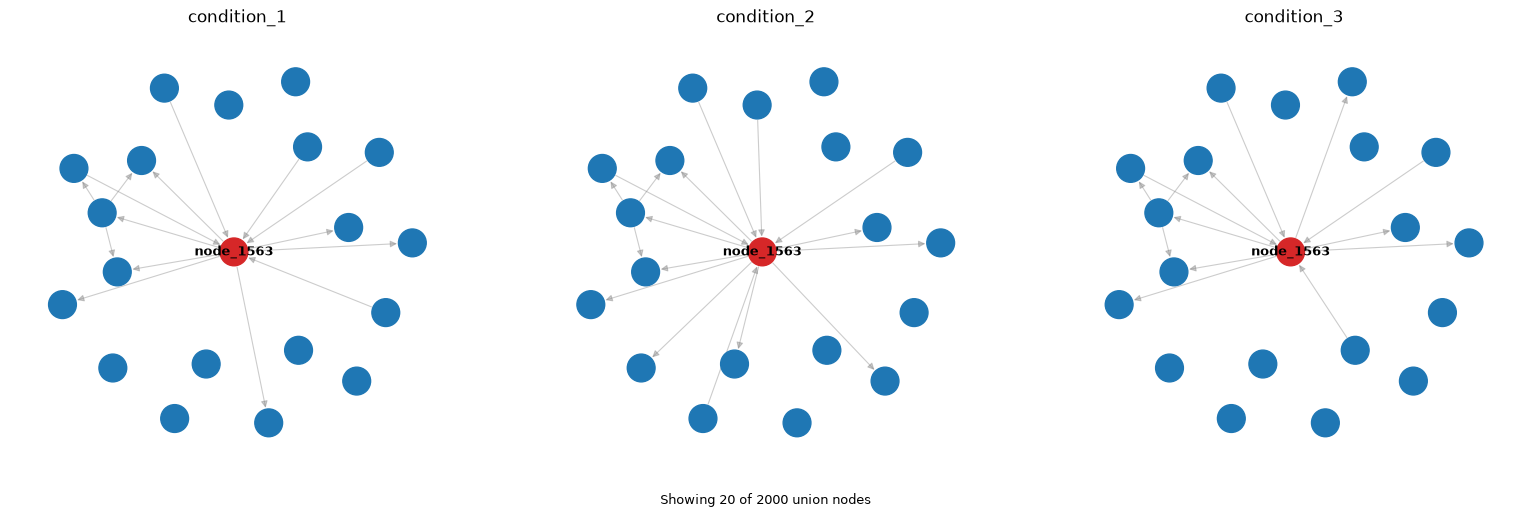

In [7]:
started = perf_counter()
figure = small_multiples_plot(
    networks, focus_node=FOCUS_NODE, radius=1, max_nodes=25,
    layout="spring", labels=[FOCUS_NODE], seed=SEED, figsize=(16, 5),
)
save_view(figure, "05_neighborhood_comparison.png", "Three condition panels", NEIGHBORHOOD_SIZE, started)

## Save the full results and check that plotting changed no scores

The scores CSV contains **all 2,000 nodes**, irrespective of the view filters.
Input CSVs are included so the exact networks can be reused. Single-run timings
include layout and PNG saving for each figure and should not be interpreted as
benchmark results or p-value performance measurements.

In [8]:
pd.testing.assert_frame_equal(scores, scores_before_plotting)
pd.testing.assert_frame_equal(rewiring_analysis(networks, backend="sparse"), scores_before_plotting)
for name, frame in raw_networks.items():
    frame.to_csv(OUTPUT_DIR / f"{name}_edges.csv", index=False)
scores.to_csv(OUTPUT_DIR / "rewiring_scores_all_nodes.csv", index=False)
input_summary.to_csv(OUTPUT_DIR / "network_summary.csv", index=False)
view_summary = pd.DataFrame(views)
view_summary.to_csv(OUTPUT_DIR / "view_summary.csv", index=False)
timing_table = pd.DataFrame(timings)
timing_table.to_csv(OUTPUT_DIR / "illustrative_run_timings.csv", index=False)
metadata = {
    "nodes_per_condition": N_NODES,
    "edges_per_condition": {name: len(frame) for name, frame in raw_networks.items()},
    "directed_union_edges": len(union_edges),
    "conditions": list(raw_networks),
    "seed": SEED,
    "focus_node": FOCUS_NODE,
    "neighborhood_nodes": len(neighbor_names),
    "checks": "All full scores retained and unchanged after plotting",
    "software_versions": {"python": python_version(), **{name: version(name) for name in
        ("dynet-py", "numpy", "pandas", "matplotlib", "networkx", "scipy")}},
    "purpose": "Synthetic plotting demonstration; not validation or a p-value benchmark",
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
display(view_summary)
display(timing_table.round({"seconds": 3}))
print("All plotting checks passed. Files saved in the example outputs/ folder.")

,view,displayed_nodes,file
0,Full network: automatic,2000,01_full_network_auto.png
1,Full network: spring,2000,02_full_network_spring.png
2,Top 40 by rewiring,40,03_top_40_nodes.png
3,One-hop neighborhood,20,04_focused_neighborhood.png
4,Three condition panels,20,05_neighborhood_comparison.png


,step,seconds
0,generate synthetic inputs,0.314
1,prepare inputs,0.096
2,sparse rewiring scores,0.005
3,01_full_network_auto.png,1.137
4,02_full_network_spring.png,32.894
5,03_top_40_nodes.png,0.264
6,04_focused_neighborhood.png,0.256
7,05_neighborhood_comparison.png,0.524


All plotting checks passed. Files saved in the example outputs/ folder.


## Try another view

Change `FOCUS_NODE`, `radius`, `top_n`, `max_nodes`, or `labels` in the plotting
cells and rerun them. Change `N_NODES` in the first code cell and restart/run all
to generate a different network size. The generator requires at least 60 nodes.

For your own inputs, replace `make_networks(...)` with a dictionary of CSV tables
and keep the preparation, scoring, and plotting calls. Remove assertions and
captions that depend on this synthetic dataset's exact node count.